# 01 — Exploratory analysis of observing conditions at the Roque de los Muchachos

**Independent project, not affiliated with GRANTECAN or any observatory.** All data are real and public:
NOT weather archive (1997→), ING R2D2 seeing monitor (2018→) and ING nightly accounting of the
William Herschel Telescope (2007→). See the README for sources.

Questions for this notebook:
1. How complete is each source, year by year?
2. Does the dome-closure rule rebuilt from humidity (close at ≥ 90 %, reopen after 20 min below)
   agree with the hours the WHT really lost to weather?
3. What does the seeing look like, and which weather variables move with it?
4. How strong are the naive baselines (persistence: "tonight = last night")? Any model must beat them.

A **night** is labelled with the date on which it starts, and only **astronomical night**
(Sun more than 18° below the horizon) is used.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from roque_forecast import config, plotting

plotting.apply_style()
BLUE, ORANGE = plotting.SERIES[0], plotting.SERIES[1]

nights = pd.read_parquet(config.PROCESSED_DIR / "nights.parquet")
nights = nights[nights.index < pd.Timestamp.now().normalize()]  # finished nights only
print(f"{len(nights):,} nights, {nights.index.min().date()} → {nights.index.max().date()}")

10,719 nights, 1997-02-03 → 2026-10-26


## 1. Data coverage

A night counts as "usable" for the weather when at least 80 % of its 10-minute blocks have NOT data;
for seeing when R2D2 recorded at least 40 values; for losses when the ING page has real accounting.

year,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
NOT weather,311,354,326,349,360,361,324,366,365,364,...,364,362,364,357,363,365,362,362,364,299
R2D2 seeing,0,0,0,0,0,0,0,0,0,0,...,0,46,260,224,206,249,289,253,283,244
WHT accounting,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


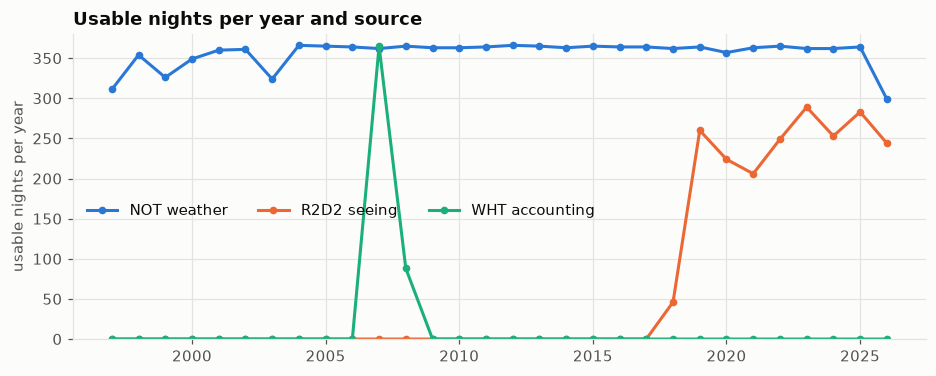

In [2]:
usable = pd.DataFrame({
    "NOT weather": nights["coverage"] >= 0.8,
    "R2D2 seeing": nights["seeing_median"].notna(),
    "WHT accounting": nights["wht_has_accounting"].fillna(False).astype(bool),
}).groupby(nights["year"]).sum()

fig, ax = plt.subplots(figsize=(10, 3.6))
for i, column in enumerate(usable.columns):
    ax.plot(usable.index, usable[column], marker="o", markersize=4, label=column, color=plotting.SERIES[i])
ax.set_ylim(0, 380)
ax.set_ylabel("usable nights per year")
ax.set_title("Usable nights per year and source")
ax.legend(loc="center left", bbox_to_anchor=(0, 0.42), ncols=3)
plotting.save(fig, "01_coverage")
usable.T

## 2. Rebuilt dome closures vs. real weather losses

The NOT public export has no rain or dome flags, so the closure is rebuilt from humidity.
If the rule is sensible, the closed fraction of each night should track the fraction of the
night the WHT (4.2 m, same mountain) lost to weather.

450 nights with both values; Pearson correlation = 0.72


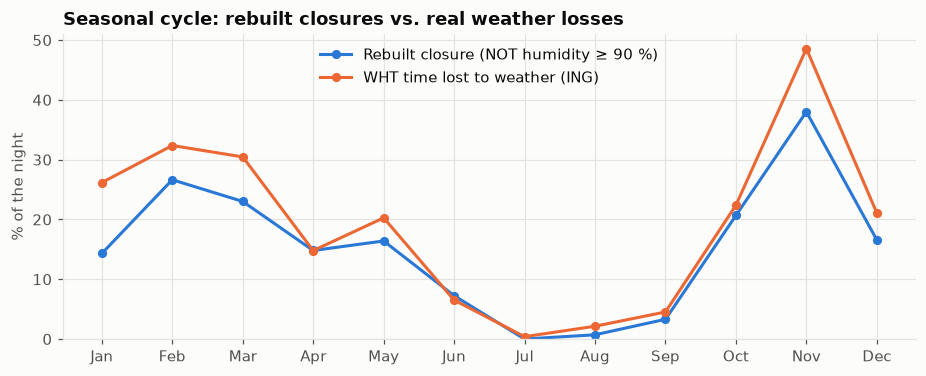

In [3]:
both = nights[["dome_closed_frac", "wht_weather_lost_frac"]].dropna()
corr = both.corr().iloc[0, 1]
print(f"{len(both):,} nights with both values; Pearson correlation = {corr:.2f}")

monthly = both.groupby(both.index.month).mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(monthly.index, monthly["dome_closed_frac"] * 100, marker="o", markersize=5, color=BLUE,
        label="Rebuilt closure (NOT humidity ≥ 90 %)")
ax.plot(monthly.index, monthly["wht_weather_lost_frac"] * 100, marker="o", markersize=5, color=ORANGE,
        label="WHT time lost to weather (ING)")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("% of the night")
ax.set_ylim(0, None)
ax.set_title("Seasonal cycle: rebuilt closures vs. real weather losses")
ax.legend(loc="upper center")
plotting.save(fig, "02_closure_vs_losses_monthly")

Night by night: how often do the two sources agree on "most of the night was lost"?

In [4]:
closed_most = both["dome_closed_frac"] > 0.5
lost_most = both["wht_weather_lost_frac"] > 0.5
agreement = pd.crosstab(closed_most.rename("rebuilt: closed > 50 %"), lost_most.rename("WHT: lost > 50 %"))
print(f"Agreement: {(closed_most == lost_most).mean():.1%} of nights")
agreement

Agreement: 89.1% of nights


WHT: lost > 50 %,False,True
rebuilt: closed > 50 %,,
False,344,35
True,14,57


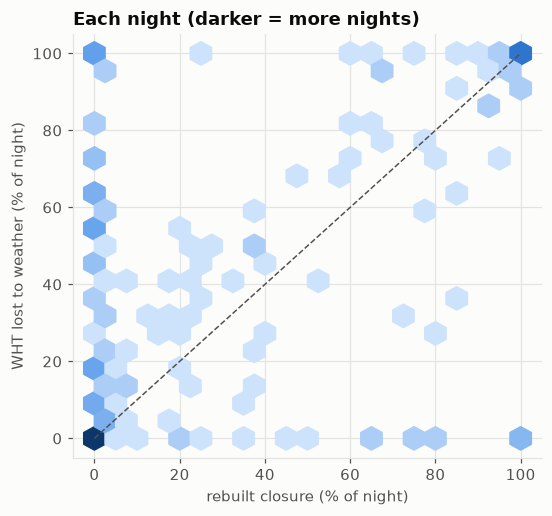

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.hexbin(both["dome_closed_frac"] * 100, both["wht_weather_lost_frac"] * 100, gridsize=20, bins="log",
          cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", plotting.BLUE_RAMP), mincnt=1)
ax.plot([0, 100], [0, 100], color=plotting.TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.set_xlabel("rebuilt closure (% of night)")
ax.set_ylabel("WHT lost to weather (% of night)")
ax.set_title("Each night (darker = more nights)")
plotting.save(fig, "02_closure_vs_losses_nights")

Nights the rule misses are the interesting ones: losses without high humidity are usually
**wind**, **dust (calima)**, **snow/ice on the dome** or clouds with dry air. They tell us which
extra inputs the closure model needs.

In [6]:
missed = both[(both["wht_weather_lost_frac"] > 0.5) & (both["dome_closed_frac"] < 0.1)]
print(f"{len(missed)} nights lost by the WHT with < 10 % rebuilt closure")
nights.loc[missed.index, ["humidity_max", "wind_max", "wind_mean", "temp_mean", "wht_weather_lost_h"]].describe().round(1)

30 nights lost by the WHT with < 10 % rebuilt closure


,humidity_max,wind_max,wind_mean,temp_mean,wht_weather_lost_h
count,30.0,30.0,30.0,30.0,30.0
mean,50.2,12.4,6.9,5.6,7.7
std,24.0,4.7,3.2,2.7,2.3
min,11.4,4.5,1.9,1.2,3.7
25%,35.7,9.6,4.3,3.7,6.0
50%,47.1,11.8,6.5,4.9,6.9
75%,66.2,15.9,9.1,6.9,9.9
max,90.0,23.3,14.6,11.9,11.0


## 3. Seeing (R2D2, nightly median)

2,054 nights. Median of nightly medians = 0.81"; 25-75 % = 0.67"–1.04"


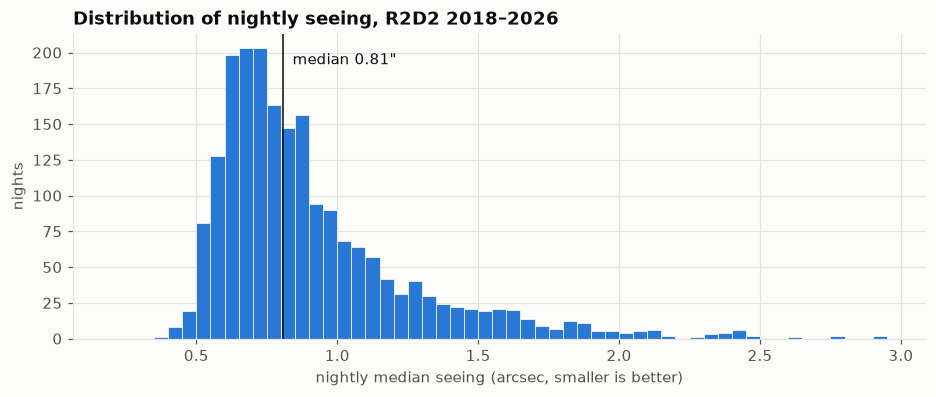

In [7]:
seeing = nights["seeing_median"].dropna()
print(f"{len(seeing):,} nights. Median of nightly medians = {seeing.median():.2f}\"; "
      f"25-75 % = {seeing.quantile(.25):.2f}\"–{seeing.quantile(.75):.2f}\"")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(seeing, bins=np.arange(0.2, 3.0, 0.05), color=BLUE, edgecolor=plotting.SURFACE, linewidth=0.5)
ax.axvline(seeing.median(), color=plotting.TEXT_PRIMARY, linewidth=1)
ax.annotate(f"median {seeing.median():.2f}\"", (seeing.median(), ax.get_ylim()[1] * 0.9),
            xytext=(6, 0), textcoords="offset points", color=plotting.TEXT_PRIMARY)
ax.set_xlabel("nightly median seeing (arcsec, smaller is better)")
ax.set_ylabel("nights")
ax.set_title("Distribution of nightly seeing, R2D2 2018–2026")
plotting.save(fig, "03_seeing_hist")

How does seeing change with the weather? We bin each variable into quantiles and plot the median
seeing per bin (robust to outliers), with the 25–75 % band.

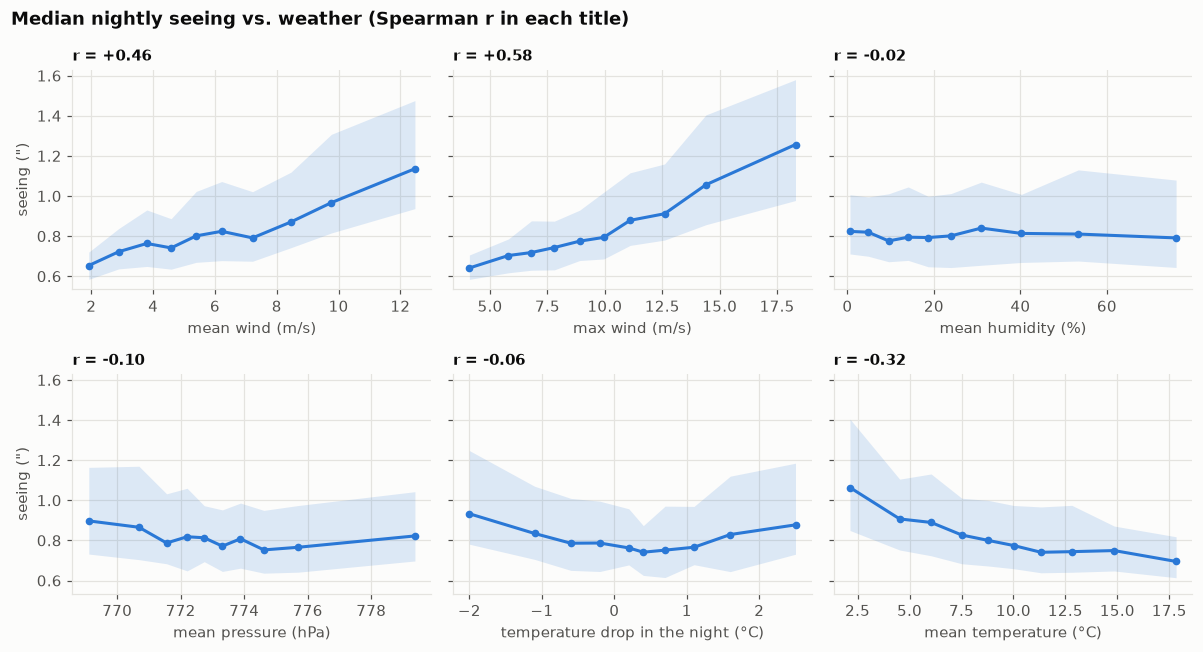

In [8]:
features = {"wind_mean": "mean wind (m/s)", "wind_max": "max wind (m/s)", "humidity_mean": "mean humidity (%)",
            "pressure_mean": "mean pressure (hPa)", "temp_drop": "temperature drop in the night (°C)",
            "temp_mean": "mean temperature (°C)"}
data = nights[list(features) + ["seeing_median"]].dropna()

fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
for ax, (column, label) in zip(axes.flat, features.items()):
    bins = pd.qcut(data[column], 10, duplicates="drop")
    stats = data.groupby(bins, observed=True)["seeing_median"].quantile([.25, .5, .75]).unstack()
    centres = data.groupby(bins, observed=True)[column].median()
    ax.fill_between(centres, stats[0.25], stats[0.75], color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(centres, stats[0.5], color=BLUE, marker="o", markersize=4)
    ax.set_xlabel(label)
    ax.set_title(f"r = {data[column].corr(data['seeing_median'], method='spearman'):+.2f}", fontsize=10)
axes[0, 0].set_ylabel("seeing (\")")
axes[1, 0].set_ylabel("seeing (\")")
fig.suptitle("Median nightly seeing vs. weather (Spearman r in each title)", x=0.01, ha="left",
             fontweight="bold", color=plotting.TEXT_PRIMARY)
fig.tight_layout()
plotting.save(fig, "03_seeing_vs_weather")

Wind direction matters at a mountain-top site: air arriving over the island's caldera is more
turbulent than air arriving from the open ocean.

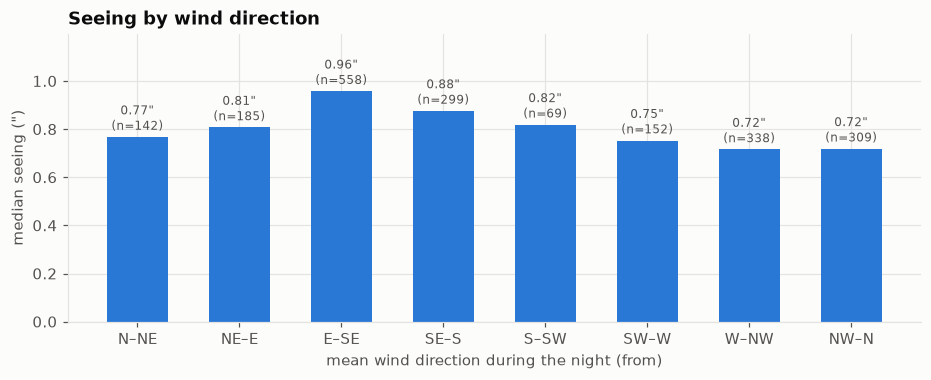

In [9]:
data = nights[["wind_dir_mean", "seeing_median"]].dropna()
sectors = pd.cut(data["wind_dir_mean"], np.arange(0, 361, 45), labels=["N–NE", "NE–E", "E–SE", "SE–S", "S–SW", "SW–W", "W–NW", "NW–N"], include_lowest=True)
by_sector = data.groupby(sectors, observed=True)["seeing_median"].agg(["median", "size"])
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(by_sector.index.astype(str), by_sector["median"], color=BLUE, width=0.6)
for x, (median, n) in enumerate(by_sector.itertuples(index=False)):
    ax.annotate(f"{median:.2f}\"\n(n={n})", (x, median), ha="center", va="bottom", fontsize=8,
                color=plotting.TEXT_SECONDARY, xytext=(0, 2), textcoords="offset points")
ax.set_ylabel("median seeing (\")")
ax.set_xlabel("mean wind direction during the night (from)")
ax.set_title("Seeing by wind direction")
ax.set_ylim(0, by_sector["median"].max() * 1.25)
plotting.save(fig, "03_seeing_by_wind_direction")

## 4. How strong is persistence?

The simplest forecast: tonight will be like last night. If last night predicts tonight well, a
model must do better than that to be useful (de Sepibus, Masciadri et al. 2026).

In [10]:
def persistence_scores(series: pd.Series) -> dict:
    daily = series.asfreq("D")
    pair = pd.DataFrame({"tonight": daily, "last_night": daily.shift(1)}).dropna()
    error = pair["tonight"] - pair["last_night"]
    climatology = pair["tonight"].groupby(pair.index.month).transform("mean")
    return {
        "nights": len(pair),
        "corr(tonight, last night)": pair.corr().iloc[0, 1],
        "persistence RMSE": np.sqrt((error ** 2).mean()),
        "monthly-climatology RMSE": np.sqrt(((pair["tonight"] - climatology) ** 2).mean()),
    }

pd.DataFrame({
    "seeing median (\")": persistence_scores(nights["seeing_median"]),
    "rebuilt closure (fraction)": persistence_scores(nights["dome_closed_frac"]),
    "WHT weather lost (fraction)": persistence_scores(nights["wht_weather_lost_frac"]),
}).round(3)

,"seeing median ("")",rebuilt closure (fraction),WHT weather lost (fraction)
nights,1745.000,10609.000,452.000
"corr(tonight, last night)",0.365,0.549,0.444
persistence RMSE,0.409,0.308,0.377
monthly-climatology RMSE,0.337,0.311,0.331


## 5. Long-term view: weather losses per year (WHT)

,lost,night,n,lost_pct
year,,,,
2007,643.8,3298.9,365,19.5


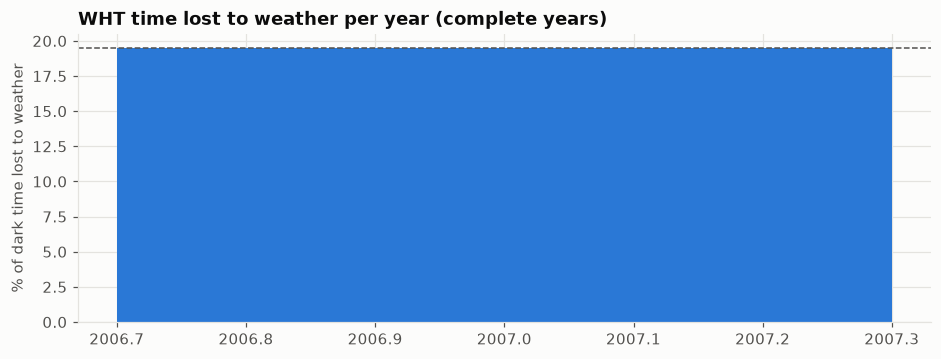

In [11]:
yearly = nights.loc[nights["wht_has_accounting"].fillna(False).astype(bool)].groupby("year").agg(
    lost=("wht_weather_lost_h", "sum"), night=("wht_night_h", "sum"), n=("wht_night_h", "size"))
yearly["lost_pct"] = (yearly["lost"] / yearly["night"]).clip(upper=1) * 100
yearly = yearly[yearly["n"] >= 300]  # complete years only

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(yearly.index, yearly["lost_pct"], color=BLUE, width=0.6)
ax.axhline(yearly["lost_pct"].mean(), color=plotting.TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.annotate(f"mean {yearly['lost_pct'].mean():.0f} %", (yearly.index.min() - 0.4, yearly["lost_pct"].mean()),
            xytext=(0, 4), textcoords="offset points", color=plotting.TEXT_SECONDARY, fontsize=9)
ax.set_ylabel("% of dark time lost to weather")
ax.set_title("WHT time lost to weather per year (complete years)")
plotting.save(fig, "05_losses_per_year")
yearly.round(1)

## Summary
Findings are written up in `reports/EDA_01.md` (and explained in Spanish in `APRENDIZAJE.md`).